# Sistema de Alerta Temprana Saber 11: modelo final y despliegue

**Inteligencia Artificial · Universidad Autónoma de Occidente · 2026-2**
Juan Sebastián Lozano Díaz · Julián David Cuéllar Cubillos · Alejandro Cárdenas Anturi
Profesores: Jesús Alfonso López y José Luis Paniagua

En el segundo entregable construimos un MLP que estima el riesgo de que un estudiante de Cali obtenga **menos de 250 puntos** en el Saber 11. En este notebook llevamos ese modelo a su versión final y lo dejamos listo para desplegar. Partimos de lo que nosotros mismos pusimos como limitaciones en la exposición anterior y de lo que nos pidió el profe:

| Lo que nos faltaba | Lo que hacemos aquí |
|---|---|
| Búsqueda de hiperparámetros (observación del profe) | Búsqueda aleatoria de 30 configuraciones y prueba de estabilidad con 3 semillas |
| Validación aleatoria dentro de 2019–2024 | Validación por año: entrenamos con 2019–2023, escogemos con 2024 y probamos una sola vez con 2025 |
| Una sola arquitectura, sin regularización | Probamos de 1 a 3 capas, Dropout y L2 |
| Salida sigmoide sin calibrar | Calibración isotónica y curva de confiabilidad |
| Casi la mitad de las alertas eran falsas | Priorización según los cupos del colegio |
| No sabíamos qué aprendió el modelo ni con quién falla | Importancia de variables, análisis por grupos y monitoreo de cambios en los datos |
| App solo en nuestro computador | Exportamos el modelo para una app web pública (ver `app/`) |

Las 13 variables y la definición del objetivo son las mismas del segundo entregable, para que la comparación sea justa.

## 1. Librerías y datos

In [1]:
import os, sys, json, time, random, warnings, logging
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # oculta los mensajes internos de TensorFlow
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss, roc_curve,
                             precision_recall_curve, precision_score, recall_score, f1_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
tf.get_logger().setLevel(logging.ERROR)             # sin avisos de retracing ni de GPU

pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROJO, GRIS, NEGRO = "#C8102E", "#9A9A9A", "#1F1F1F"
IS_COLAB = "google.colab" in sys.modules
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [2]:
# En Colab leemos el archivo desde Drive (o lo subimos); en nuestro computador, desde la carpeta del proyecto.
ARCHIVO = "saber11_cali_2019_2025_limpio.csv"
if IS_COLAB:
    from google.colab import drive, files
    try:
        drive.mount("/content/gdrive")
    except Exception:
        print("No se pudo conectar el Drive.")
    ruta = Path("/content/gdrive/MyDrive/Proyecto_Final_Saber11") / ARCHIVO
    if not ruta.exists():
        print("No encontramos el archivo en el Drive. Súbelo aquí:", ARCHIVO)
        ruta = Path(list(files.upload().keys())[0])
else:
    ruta = Path("../data/processed") / ARCHIVO

datos = pd.read_csv(ruta)
print("Registros:", len(datos), "| columnas:", datos.shape[1])

Registros: 128260 | columnas: 16


## 2. Variables y objetivo
Las mismas del segundo entregable: 12 variables categóricas del colegio, la familia y el estudiante, más la edad en grupos. Los faltantes quedan como la categoría **«No reportado»**, porque en la vida real el colegio tampoco va a tener siempre todas las respuestas y el modelo tiene que funcionar igual. La clase 1 es puntaje global **menor a 250**.

In [3]:
VARIABLES = ["cole_jornada", "cole_calendario", "cole_naturaleza", "cole_area_ubicacion", "cole_bilingue",
             "cole_caracter", "fami_tieneinternet", "fami_tienecomputador", "fami_educacionmadre",
             "fami_educacionpadre", "fami_estratovivienda", "estu_genero", "grupo_edad"]

def preparar(d):
    d = d.copy()
    edad = pd.to_numeric(d["edad"], errors="coerce")
    condiciones = [edad < 16, (edad >= 16) & (edad < 17), (edad >= 17) & (edad < 18), (edad >= 18) & (edad < 19),
                   (edad >= 19) & (edad < 20), (edad >= 20) & (edad < 25), (edad >= 25) & (edad < 30), edad >= 30]
    etiquetas = ["15 o menos", "16", "17", "18", "19", "20 a 24", "25 a 29", "30 o más"]
    d["grupo_edad"] = np.select(condiciones, etiquetas, default="No reportado")
    for c in VARIABLES:
        d[c] = d[c].astype("string").fillna("No reportado").astype(str)
    return d

datos = preparar(datos)
datos["anio"] = datos["periodo"].astype(str).str[:4].astype(int)
datos["y"] = (datos["punt_global"] < 250).astype(int)
display(datos.groupby("anio").agg(estudiantes=("y", "size"), porcentaje_bajo_250=("y", "mean")).round(3))

,estudiantes,porcentaje_bajo_250
anio,,
2019,21788,0.447
2020,20030,0.446
2022,22289,0.434
2023,22290,0.428
2024,21099,0.414
2025,20764,0.402


## 3. Una partición que respeta el tiempo
En el segundo entregable la validación salía al azar de 2019–2024, así que el modelo se ajustaba con estudiantes del mismo año con que se validaba. Ahora separamos por año, que es como se usaría el sistema: se entrena con lo que ya pasó y se aplica a una cohorte nueva.

- **Entrenamiento:** 2019, 2020, 2022 y 2023.
- **2024**, dividido en dos mitades al azar:
  - **Selección:** para comparar hiperparámetros y detener el entrenamiento.
  - **Calibración:** para calibrar las probabilidades y fijar el umbral. La separamos para no calibrar con los mismos datos con que escogimos el modelo.
- **Prueba: 2025.** No se usa para ninguna decisión; se mira una sola vez al final.

In [4]:
train = datos[datos.anio <= 2023]
v2024 = datos[datos.anio == 2024]
test = datos[datos.anio == 2025]
seleccion, calibracion = train_test_split(v2024, test_size=0.5, random_state=42, stratify=v2024.y)

for nombre, d in [("Entrenamiento 2019-2023", train), ("2024 selección", seleccion), ("2024 calibración", calibracion), ("Prueba 2025", test)]:
    print(f"{nombre:25s} {len(d):7,d} estudiantes | {d.y.mean():.1%} por debajo de 250")

# El one-hot aprende las categorías SOLO con entrenamiento
pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), VARIABLES)])
X_tr = pre.fit_transform(train[VARIABLES]).astype("float32")
X_sel, X_cal, X_te = [pre.transform(d[VARIABLES]).astype("float32") for d in (seleccion, calibracion, test)]
y_tr, y_sel, y_cal, y_te = train.y.values, seleccion.y.values, calibracion.y.values, test.y.values
print("\nColumnas después del one-hot:", X_tr.shape[1])

Entrenamiento 2019-2023    86,397 estudiantes | 43.8% por debajo de 250
2024 selección             10,549 estudiantes | 41.4% por debajo de 250
2024 calibración           10,550 estudiantes | 41.4% por debajo de 250
Prueba 2025                20,764 estudiantes | 40.2% por debajo de 250



Columnas después del one-hot: 72


El porcentaje de estudiantes por debajo de 250 baja con los años (de 43,8 % en entrenamiento a 40,2 % en 2025). Eso ya es un cambio en los datos que el modelo va a tener que soportar, y es una de las razones para monitorear el modelo después de desplegarlo (sección 10).

## 4. Puntos de comparación
Antes de buscar la mejor red entrenamos, con exactamente la misma partición:
- **Estrato (tasa histórica):** el riesgo de cada estudiante es el porcentaje de estudiantes de su estrato que quedó por debajo de 250. Es lo que haría alguien sin modelo.
- **Regresión logística** y **Gradient Boosting:** modelos clásicos.
- **La red V3** del segundo entregable (64-32, sin regularización, lotes de 32), reentrenada con esta partición.

Comparamos con el **AUC**, que mide qué tan bien el modelo ordena a los estudiantes por riesgo sin depender de un umbral.

In [5]:
logistica = LogisticRegression(max_iter=2000).fit(X_tr, y_tr)
boosting = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42).fit(X_tr, y_tr)
tasa_estrato = train.groupby("fami_estratovivienda").y.mean()
lineas_base = {
    "Estrato (tasa histórica)": lambda d, X: d.fami_estratovivienda.map(tasa_estrato).fillna(y_tr.mean()).values,
    "Regresión logística": lambda d, X: logistica.predict_proba(X)[:, 1],
    "Gradient Boosting": lambda d, X: boosting.predict_proba(X)[:, 1],
}
for nombre, f in lineas_base.items():
    print(f"{nombre:26s} AUC 2024-selección = {roc_auc_score(y_sel, f(seleccion, X_sel)):.4f}")

Estrato (tasa histórica)   AUC 2024-selección = 0.5980
Regresión logística        AUC 2024-selección = 0.7473
Gradient Boosting          AUC 2024-selección = 0.7551


In [6]:
def construir(cfg, n_entradas):
    reg = regularizers.l2(cfg["l2"]) if cfg["l2"] > 0 else None
    modelo = keras.Sequential([layers.Input(shape=(n_entradas,))])
    for neuronas in cfg["capas"]:
        modelo.add(layers.Dense(neuronas, activation="relu", kernel_regularizer=reg))
        if cfg["dropout"] > 0:
            modelo.add(layers.Dropout(cfg["dropout"]))
    modelo.add(layers.Dense(1, activation="sigmoid"))
    modelo.compile(optimizer=keras.optimizers.Adam(cfg["lr"]), loss="binary_crossentropy",
                   metrics=[keras.metrics.AUC(name="auc")])
    return modelo

def entrenar(cfg, semilla=42, paciencia=5, max_epocas=60):
    # EarlyStopping mira la pérdida en 2024-selección y devuelve los pesos de la mejor época
    keras.utils.set_random_seed(semilla)
    modelo = construir(cfg, X_tr.shape[1]); t0 = time.time()
    hist = modelo.fit(X_tr, y_tr, validation_data=(X_sel, y_sel), epochs=max_epocas, batch_size=cfg["batch"], verbose=0,
                      callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True)])
    p = modelo.predict(X_sel, verbose=0, batch_size=4096).ravel()
    return modelo, hist, {"AUC 2024": roc_auc_score(y_sel, p), "log loss 2024": log_loss(y_sel, p),
                          "épocas": len(hist.history["loss"]), "parámetros": modelo.count_params(), "segundos": round(time.time() - t0, 1)}

V3 = dict(capas=[64, 32], dropout=0.0, l2=0.0, lr=1e-3, batch=32)
modelo_v3, hist_v3, r_v3 = entrenar(V3)
print("Red V3 (64-32):", {k: round(v, 4) if isinstance(v, float) else v for k, v in r_v3.items()})

Red V3 (64-32): {'AUC 2024': 0.7489, 'log loss 2024': 0.5813, 'épocas': 6, 'parámetros': 6785, 'segundos': 23.0}


## 5. Búsqueda de hiperparámetros
Esta es la parte que nos faltó en el segundo entregable. Probamos combinaciones de:

| Hiperparámetro | Valores | Por qué |
|---|---|---|
| Capas y neuronas | 32 · 64 · 128 · 64-32 · 128-64 · 256-128 · 128-64-32 · 256-128-64 | Ver si la red necesita más capacidad que la V3 |
| Dropout | 0 · 0,2 · 0,3 · 0,5 | En la V3 vimos sobreajuste desde la época 4 |
| L2 | 0 · 1e-5 · 1e-4 · 1e-3 | Otra forma de frenar el sobreajuste: castiga los pesos grandes |
| Tasa de aprendizaje (Adam) | 3e-4 · 1e-3 · 3e-3 | Qué tan grandes son los pasos del descenso de gradiente |
| Tamaño de lote | 64 · 256 · 1024 | Lotes grandes dan gradientes más estables y entrenan más rápido |

Son 8 × 4 × 4 × 3 × 3 = 1 152 combinaciones, demasiadas para probarlas todas. Por eso usamos **búsqueda aleatoria** de 30 combinaciones. Bergstra y Bengio (2012) mostraron que suele encontrar configuraciones tan buenas como la búsqueda en malla con muchas menos pruebas, porque no gasta intentos en los hiperparámetros que importan poco. Todas las combinaciones se comparan con el AUC en **2024-selección**.

In [7]:
ESPACIO = dict(capas=[[32], [64], [128], [64, 32], [128, 64], [256, 128], [128, 64, 32], [256, 128, 64]],
               dropout=[0.0, 0.2, 0.3, 0.5], l2=[0.0, 1e-5, 1e-4, 1e-3], lr=[3e-4, 1e-3, 3e-3], batch=[64, 256, 1024])
azar = random.Random(2026)
busqueda = []
for i in range(30):
    cfg = {k: azar.choice(v) for k, v in ESPACIO.items()}
    _, _, r = entrenar(cfg)
    busqueda.append({**r, "capas": "-".join(map(str, cfg["capas"])), "dropout": cfg["dropout"], "l2": cfg["l2"],
                     "lr": cfg["lr"], "lote": cfg["batch"], "cfg": cfg})
tabla_busqueda = pd.DataFrame(busqueda).sort_values("AUC 2024", ascending=False).reset_index(drop=True)
tabla_busqueda.index += 1
display(tabla_busqueda.drop(columns="cfg").head(10).round(4))

,AUC 2024,log loss 2024,épocas,parámetros,segundos,capas,dropout,l2,lr,lote
1,0.7553,0.5758,44,17665,20.6,128-64,0.3,0.0010,0.0003,1024
2,0.7548,0.5746,20,59905,13.5,256-128-64,0.5,0.0010,0.0010,1024
3,0.7547,0.5750,24,4737,16.2,64,0.5,0.0010,0.0003,256
4,0.7545,0.5757,25,4737,16.7,64,0.2,0.0010,0.0003,256
5,0.7544,0.5764,14,17665,8.1,128-64,0.5,0.0001,0.0030,1024
6,0.7544,0.5774,19,59905,24.8,256-128-64,0.5,0.0010,0.0003,256
7,0.7540,0.5765,18,2369,32.9,32,0.3,0.0001,0.0003,64
8,0.7540,0.5769,14,2369,4.1,32,0.0,0.0000,0.0010,1024
9,0.7538,0.5777,25,2369,15.1,32,0.5,0.0001,0.0003,256
10,0.7537,0.5777,14,17665,7.1,128-64,0.3,0.0001,0.0010,1024


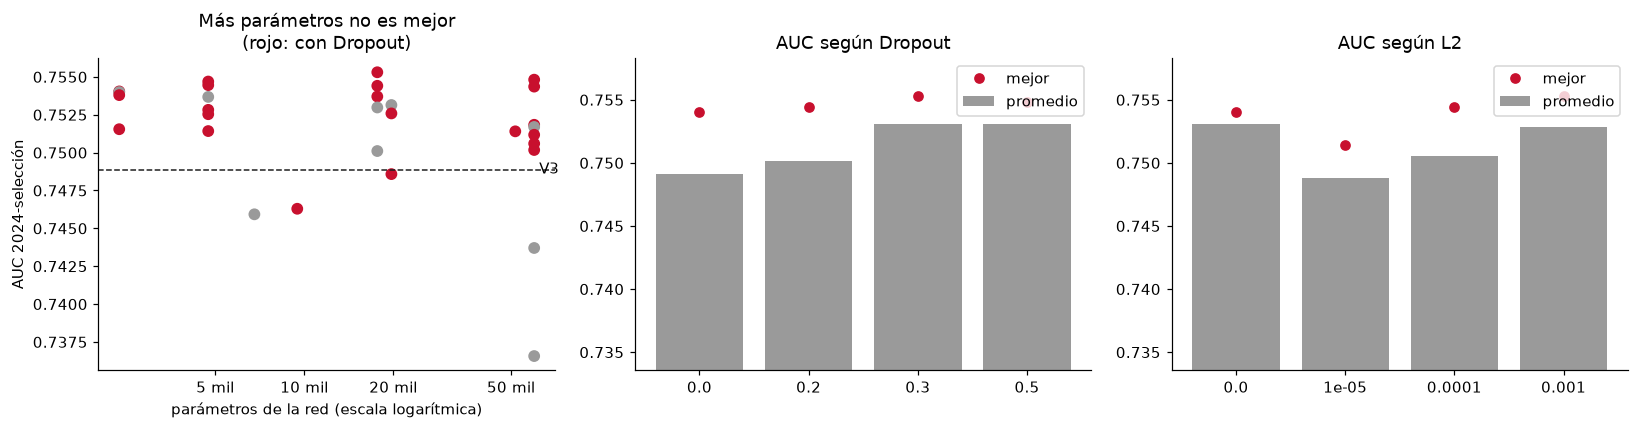

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
tb = tabla_busqueda
ejes[0].scatter(tb["parámetros"], tb["AUC 2024"], c=[ROJO if d > 0 else GRIS for d in tb.dropout], s=45)
ejes[0].axhline(r_v3["AUC 2024"], ls="--", c=NEGRO, lw=1); ejes[0].text(tb["parámetros"].max(), r_v3["AUC 2024"], " V3", va="center")
ejes[0].set_xscale("log"); ejes[0].set_xlabel("parámetros de la red (escala logarítmica)")
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator
ejes[0].xaxis.set_major_locator(FixedLocator([5000, 10000, 20000, 50000]))
ejes[0].xaxis.set_major_formatter(FixedFormatter(["5 mil", "10 mil", "20 mil", "50 mil"]))
ejes[0].xaxis.set_minor_locator(NullLocator()); ejes[0].set_ylabel("AUC 2024-selección")
ejes[0].set_title("Más parámetros no es mejor\n(rojo: con Dropout)")
for ax, col, tit in [(ejes[1], "dropout", "Dropout"), (ejes[2], "l2", "L2")]:
    g = tb.groupby(col)["AUC 2024"].agg(["mean", "max"])
    ax.bar([str(x) for x in g.index], g["mean"], color=GRIS, label="promedio")
    ax.plot([str(x) for x in g.index], g["max"], "o", c=ROJO, label="mejor")
    ax.set_ylim(tb["AUC 2024"].min() - 0.003, tb["AUC 2024"].max() + 0.003); ax.set_title(f"AUC según {tit}"); ax.legend()
plt.tight_layout(); plt.show()

**Lo que encontramos.** Todas las redes quedan en un rango estrecho de AUC (más o menos entre 0,74 y 0,755): con estas 13 variables hay un techo, y más capas o más neuronas no lo rompen. Las redes grandes sin regularización son las peores, porque sobreajustan rápido. Lo que sí ayuda es la **regularización** (Dropout y L2) combinada con una **tasa de aprendizaje baja y lotes grandes**, que hacen el entrenamiento más estable. Esto confirma lo que vimos en las curvas de la V3: el problema no era la falta de capacidad, sino el sobreajuste.

### 5.1 ¿La mejor configuración ganó por suerte?
Con diferencias tan pequeñas, una configuración puede quedar de primera solo por la semilla con que empezaron los pesos. Por eso repetimos las tres mejores con tres semillas y nos quedamos con la de mejor **promedio**.

In [9]:
estabilidad = []
for _, fila in tabla_busqueda.head(3).iterrows():
    aucs = [entrenar(fila.cfg, semilla=s)[2]["AUC 2024"] for s in (42, 7, 123)]
    estabilidad.append({"configuración": f"{fila.capas} · drop {fila.dropout} · L2 {fila.l2} · lr {fila.lr} · lote {fila.lote}",
                        "AUC semilla 42": aucs[0], "AUC semilla 7": aucs[1], "AUC semilla 123": aucs[2],
                        "promedio": np.mean(aucs), "desviación": np.std(aucs), "cfg": fila.cfg})
estabilidad = pd.DataFrame(estabilidad).sort_values("promedio", ascending=False)
display(estabilidad.drop(columns="cfg").round(4))
MEJOR = estabilidad.iloc[0]["cfg"]
print("Configuración elegida:", MEJOR)

,configuración,AUC semilla 42,AUC semilla 7,AUC semilla 123,promedio,desviación
0,128-64 · drop 0.3 · L2 0.001 · lr 0.0003 · lot...,0.7553,0.7550,0.7539,0.7547,0.0006
2,64 · drop 0.5 · L2 0.001 · lr 0.0003 · lote 256,0.7547,0.7548,0.7537,0.7544,0.0005
1,256-128-64 · drop 0.5 · L2 0.001 · lr 0.001 · ...,0.7548,0.7537,0.7528,0.7538,0.0008


Configuración elegida: {'capas': [128, 64], 'dropout': 0.3, 'l2': 0.001, 'lr': 0.0003, 'batch': 1024}


## 6. El modelo final

In [10]:
modelo, hist, r_final = entrenar(MEJOR)
modelo.summary()
print({k: round(v, 4) if isinstance(v, float) else v for k, v in r_final.items()})

Model: "sequential_40"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_121 (Dense)               │ (None, 128)            │         9,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_59 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_122 (Dense)               │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_60 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_123 (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,997 (207.02 KB)

 Trainable params: 17,665 (69.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 35,332 (138.02 KB)

{'AUC 2024': 0.7553, 'log loss 2024': 0.5758, 'épocas': 44, 'parámetros': 17665, 'segundos': 20.0}


In [11]:
# Cálculo de parámetros a mano: entradas × neuronas + sesgos, capa por capa
n_in, capas = X_tr.shape[1], MEJOR["capas"]
tamanos = [n_in] + capas + [1]
filas = [{"capa": f"{'Oculta ' + str(i + 1) if i < len(capas) else 'Salida'}", "cuenta": f"{a} × {b} + {b}", "parámetros": a * b + b}
         for i, (a, b) in enumerate(zip(tamanos[:-1], tamanos[1:]))]
tabla_param = pd.DataFrame(filas); display(tabla_param)
assert tabla_param["parámetros"].sum() == modelo.count_params()
print("Total:", tabla_param["parámetros"].sum(), "= lo que cuenta Keras. La V3 tenía", modelo_v3.count_params())

,capa,cuenta,parámetros
0,Oculta 1,72 × 128 + 128,9344
1,Oculta 2,128 × 64 + 64,8256
2,Salida,64 × 1 + 1,65


Total: 17665 = lo que cuenta Keras. La V3 tenía 6785


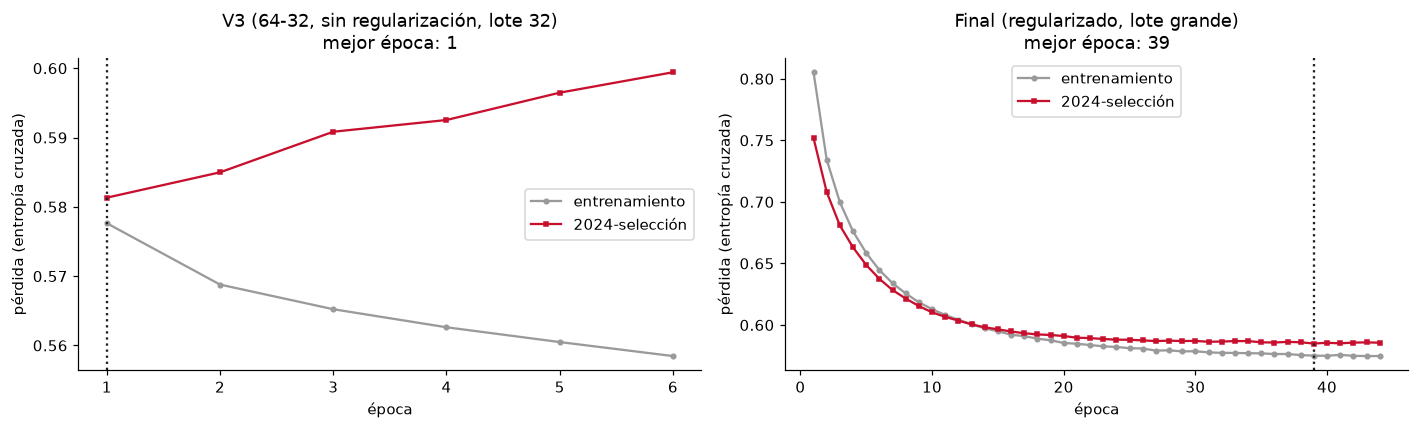

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (nombre, h) in zip(ejes, [("V3 (64-32, sin regularización, lote 32)", hist_v3), ("Final (regularizado, lote grande)", hist)]):
    ep = range(1, len(h.history["loss"]) + 1)
    ax.plot(ep, h.history["loss"], "o-", c=GRIS, ms=3, label="entrenamiento")
    ax.plot(ep, h.history["val_loss"], "s-", c=ROJO, ms=3, label="2024-selección")
    mejor = int(np.argmin(h.history["val_loss"])) + 1
    ax.axvline(mejor, ls=":", c=NEGRO); ax.set_title(f"{nombre}\nmejor época: {mejor}")
    ax.set_xlabel("época"); ax.set_ylabel("pérdida (entropía cruzada)"); ax.legend()
plt.tight_layout(); plt.show()

La diferencia se ve en las curvas. En la V3 la pérdida de validación toca fondo muy temprano y después sube mientras la de entrenamiento sigue bajando: eso es sobreajuste. En el modelo final las dos curvas bajan juntas durante muchas más épocas. Con Dropout, L2 y una tasa de aprendizaje baja, la red aprende más despacio pero no se memoriza a los estudiantes de entrenamiento.

## 7. Calibración y umbral
**Calibrar** quiere decir que la probabilidad que da el modelo se pueda leer tal cual: si dice 70 %, de cada 10 estudiantes con ese valor unos 7 deberían quedar por debajo de 250. Para un coordinador eso es importante, porque va a leer el porcentaje literalmente. Usamos **regresión isotónica**: una función escalonada que solo puede subir y que corrige la probabilidad de la red. La ajustamos con **2024-calibración**, que ni la red ni la búsqueda vieron.

Para el **umbral** mantenemos el criterio del segundo entregable: un estudiante en riesgo sin alerta es el error más costoso. Escogemos el umbral más alto que todavía detecta **al menos el 85 %** de los estudiantes en riesgo en 2024-calibración.

In [13]:
p_cal_cruda = modelo.predict(X_cal, verbose=0, batch_size=4096).ravel()
isotonica = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_cal_cruda, y_cal)
calibrar = lambda p: isotonica.predict(p)
p_cal = calibrar(p_cal_cruda)

candidatos = np.round(np.arange(0.05, 0.71, 0.01), 2)
def umbral_para(y, p, meta=0.85):
    return float(max(u for u in candidatos if recall_score(y, (p >= u).astype(int)) >= meta))

UMBRAL = umbral_para(y_cal, p_cal)
cal_A = calibracion.cole_calendario.values == "A"
UMBRAL_CAL = {"A": umbral_para(y_cal[cal_A], p_cal[cal_A]), "B": umbral_para(y_cal[~cal_A], p_cal[~cal_A])}
print("Umbral único:", UMBRAL, "| umbral por calendario:", UMBRAL_CAL)

Umbral único: 0.3 | umbral por calendario: {'A': 0.32, 'B': 0.14}


**¿Por qué un umbral por calendario?** En el segundo entregable notamos que el modelo detectaba muy pocos estudiantes en riesgo de calendario B. En los colegios de calendario B (casi todos privados) solo cerca del 20 % queda por debajo de 250, así que sus probabilidades son bajas y casi nunca pasan un umbral pensado para todo Cali. Con un umbral propio para cada calendario, escogido con el mismo criterio del 85 %, el sistema trata a los dos grupos con la misma regla. Abajo comparamos las dos opciones en 2025.

## 8. Prueba final en 2025
Ya está todo fijado: arquitectura, pesos, calibración y umbrales. Ahora sí miramos **2025, una sola vez**.

In [14]:
p_te_cruda = modelo.predict(X_te, verbose=0, batch_size=4096).ravel()
p_te = calibrar(p_te_cruda)
p_te_v3 = modelo_v3.predict(X_te, verbose=0, batch_size=4096).ravel()

def metricas(y, p, umbral):
    pred = (p >= umbral).astype(int)
    return {"AUC": roc_auc_score(y, p), "AUC-PR": average_precision_score(y, p), "Brier": brier_score_loss(y, p),
            "Sensibilidad": recall_score(y, pred), "Precisión": precision_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred), "Exactitud": accuracy_score(y, pred), "Alertas": int(pred.sum())}

umbral_cal_te = test.cole_calendario.map(UMBRAL_CAL).fillna(UMBRAL).values
resultados = pd.DataFrame({
    "MLP final · umbral por calendario": metricas(y_te, p_te, umbral_cal_te),
    "MLP final · umbral único": metricas(y_te, p_te, UMBRAL),
    "Red V3 (64-32) · umbral 0,35": metricas(y_te, p_te_v3, 0.35),
    **{f"{k} · umbral 0,5": metricas(y_te, f(test, X_te), 0.5) for k, f in lineas_base.items()},
}).T
display(resultados.round(4))

,AUC,AUC-PR,Brier,Sensibilidad,Precisión,F1,Exactitud,Alertas
MLP final · umbral por calendario,0.7544,0.6619,0.1949,0.8442,0.5215,0.6447,0.6261,13509.0
MLP final · umbral único,0.7544,0.6619,0.1949,0.8718,0.5166,0.6488,0.6206,14082.0
"Red V3 (64-32) · umbral 0,35",0.7506,0.6646,0.1966,0.8298,0.5331,0.6492,0.6395,12990.0
"Estrato (tasa histórica) · umbral 0,5",0.6000,0.4711,0.2354,0.3942,0.4995,0.4407,0.5978,6586.0
"Regresión logística · umbral 0,5",0.7457,0.6591,0.1993,0.6071,0.6061,0.6066,0.6835,8359.0
"Gradient Boosting · umbral 0,5",0.7544,0.6693,0.1961,0.6135,0.6100,0.6118,0.6871,8393.0


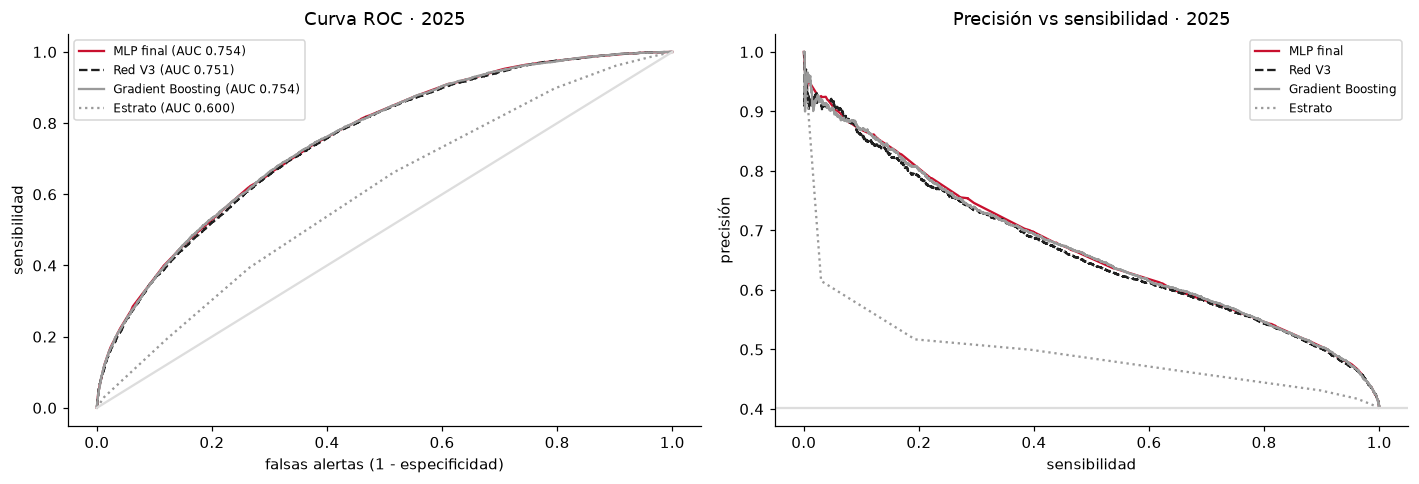

In [15]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
curvas = [("MLP final", p_te, ROJO, "-"), ("Red V3", p_te_v3, NEGRO, "--"),
          ("Gradient Boosting", lineas_base["Gradient Boosting"](test, X_te), GRIS, "-"),
          ("Estrato", lineas_base["Estrato (tasa histórica)"](test, X_te), GRIS, ":")]
for nombre, p, c, ls in curvas:
    fpr, tpr, _ = roc_curve(y_te, p); ejes[0].plot(fpr, tpr, ls=ls, c=c, label=f"{nombre} (AUC {roc_auc_score(y_te, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p); ejes[1].plot(rc, pr, ls=ls, c=c, label=nombre)
ejes[0].plot([0, 1], [0, 1], c="#DDD"); ejes[0].set_xlabel("falsas alertas (1 - especificidad)"); ejes[0].set_ylabel("sensibilidad"); ejes[0].set_title("Curva ROC · 2025")
ejes[1].axhline(y_te.mean(), c="#DDD"); ejes[1].set_xlabel("sensibilidad"); ejes[1].set_ylabel("precisión"); ejes[1].set_title("Precisión vs sensibilidad · 2025")
for ax in ejes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [16]:
# ¿La mejora frente a la V3 es real o es ruido? Bootstrap: remuestreamos los 20.764 estudiantes 1.000 veces
rng = np.random.default_rng(0); difs, aucs = [], []
for _ in range(1000):
    i = rng.integers(0, len(y_te), len(y_te))
    a = roc_auc_score(y_te[i], p_te_cruda[i]); difs.append(a - roc_auc_score(y_te[i], p_te_v3[i])); aucs.append(a)
print(f"AUC final 2025: {roc_auc_score(y_te, p_te_cruda):.4f}  (IC 95 %: {np.percentile(aucs, 2.5):.4f} – {np.percentile(aucs, 97.5):.4f})")
print(f"Mejora frente a la V3: {np.mean(difs):+.4f}  (IC 95 %: {np.percentile(difs, 2.5):+.4f} a {np.percentile(difs, 97.5):+.4f})")

AUC final 2025: 0.7550  (IC 95 %: 0.7486 – 0.7618)
Mejora frente a la V3: +0.0044  (IC 95 %: +0.0028 a +0.0060)


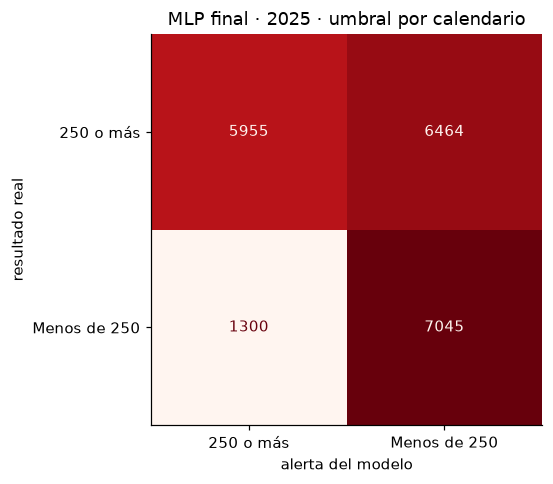

In [17]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_te, (p_te >= umbral_cal_te).astype(int)),
                       display_labels=["250 o más", "Menos de 250"]).plot(ax=ax, cmap="Reds", values_format="d", colorbar=False)
ax.set_title("MLP final · 2025 · umbral por calendario"); ax.set_xlabel("alerta del modelo"); ax.set_ylabel("resultado real")
plt.tight_layout(); plt.show()

**Lectura de los resultados.**
- La red final ordena mejor a los estudiantes que la V3 con la misma partición. La mejora es pequeña (unas cuatro milésimas de AUC), pero el intervalo de confianza no incluye el cero, así que es real y no ruido.
- Queda empatada con Gradient Boosting y muy por encima de la línea base del estrato. Que un modelo de árboles y una red lleguen al mismo techo indica que el límite está en la información de las 13 variables, no en el algoritmo.
- Con el umbral por calendario la sensibilidad total queda en el mismo nivel del segundo entregable, con algo menos de alertas.

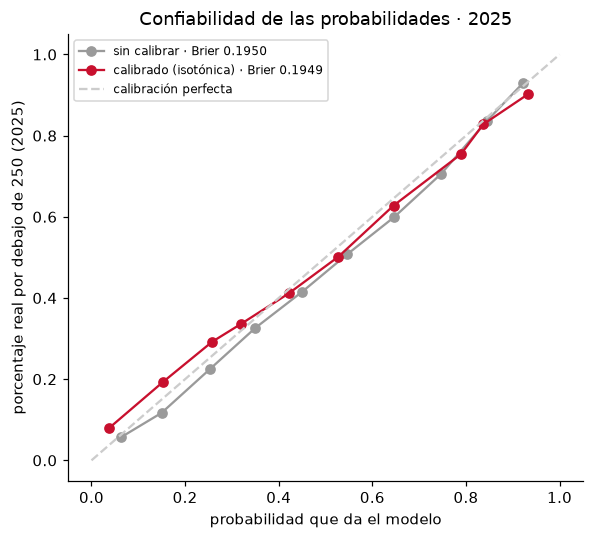

In [18]:
# Curva de confiabilidad: si el modelo dice p, ¿qué porcentaje real hay?
bins = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(5.5, 5))
for nombre, p, c in [("sin calibrar", p_te_cruda, GRIS), ("calibrado (isotónica)", p_te, ROJO)]:
    idx = np.digitize(p, bins[1:-1]); xs, ys = [], []
    for b in range(10):
        if (idx == b).sum() > 50: xs.append(p[idx == b].mean()); ys.append(y_te[idx == b].mean())
    ax.plot(xs, ys, "o-", c=c, label=f"{nombre} · Brier {brier_score_loss(y_te, p):.4f}")
ax.plot([0, 1], [0, 1], ls="--", c="#CCC", label="calibración perfecta")
ax.set_xlabel("probabilidad que da el modelo"); ax.set_ylabel("porcentaje real por debajo de 250 (2025)")
ax.set_title("Confiabilidad de las probabilidades · 2025"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

La red ya salía bastante calibrada, porque se entrena con entropía cruzada y esa pérdida castiga las probabilidades exageradas. La isotónica la acerca un poco más a la diagonal. Lo importante es que ahora está **medido**: cuando la app muestra un porcentaje, ese porcentaje se puede leer como una frecuencia real.

## 9. ¿Qué aprendió el modelo y con quién falla?
### 9.1 Priorizar según los cupos del colegio
Un colegio no puede acompañar a todos sus estudiantes. Si ordenamos a los de 2025 por riesgo y el colegio atiende solo al primer 5 %, 10 % o 20 %, ¿qué tan acertada es esa lista?

,atiende al top,"de esos, cuántos sí estaban en riesgo","del total en riesgo, cuántos alcanza"
0,5 %,0.866,0.108
1,10 %,0.803,0.200
2,15 %,0.756,0.282
3,20 %,0.714,0.355
4,30 %,0.655,0.489
5,40 %,0.615,0.612
6,50 %,0.577,0.718


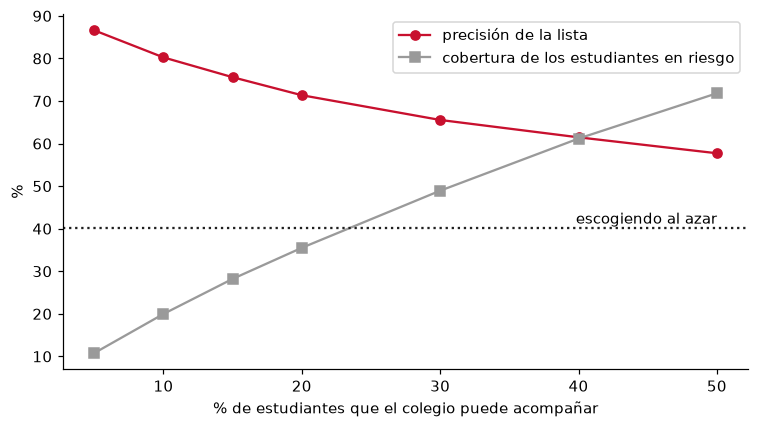

In [19]:
orden = np.argsort(-p_te); filas = []
for k in (5, 10, 15, 20, 30, 40, 50):
    sel = orden[: int(len(y_te) * k / 100)]
    filas.append({"atiende al top": f"{k} %", "de esos, cuántos sí estaban en riesgo": y_te[sel].mean(),
                  "del total en riesgo, cuántos alcanza": y_te[sel].sum() / y_te.sum()})
capacidad = pd.DataFrame(filas); display(capacidad.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([int(f[:-2]) for f in capacidad["atiende al top"]], capacidad.iloc[:, 1] * 100, "o-", c=ROJO, label="precisión de la lista")
ax.plot([int(f[:-2]) for f in capacidad["atiende al top"]], capacidad.iloc[:, 2] * 100, "s-", c=GRIS, label="cobertura de los estudiantes en riesgo")
ax.axhline(y_te.mean() * 100, ls=":", c=NEGRO); ax.text(50, y_te.mean() * 100 + 1, "escogiendo al azar", ha="right")
ax.set_xlabel("% de estudiantes que el colegio puede acompañar"); ax.set_ylabel("%"); ax.legend(); plt.tight_layout(); plt.show()

Esta curva es la que mejor responde a la necesidad del colegio. Si solo hay cupo para el 10 % de sus estudiantes, **8 de cada 10** que el modelo pone de primeros sí terminan por debajo de 250. Escogiendo al azar serían 4 de cada 10. Por eso la app permite trabajar **por cupos** además de por umbral.

### 9.2 Importancia de las variables
Para cada variable, desordenamos sus valores en 2025 y medimos cuánto cae el AUC. Si cae mucho, el modelo dependía de esa variable.

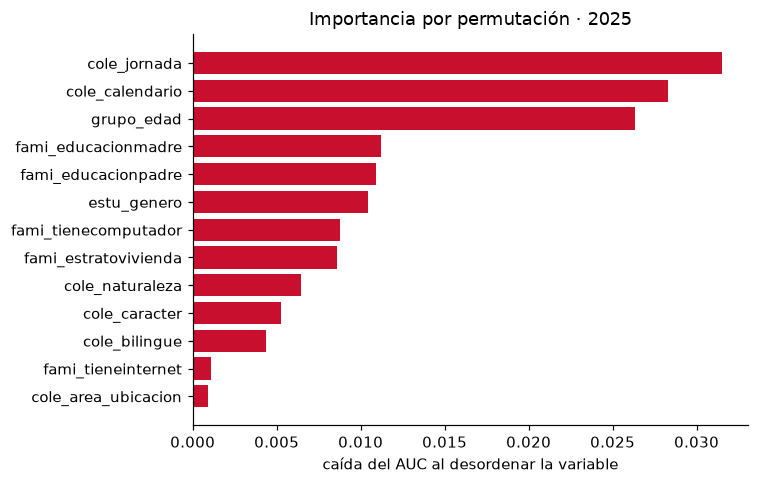

In [20]:
auc_base = roc_auc_score(y_te, p_te_cruda); imp = []
for c in VARIABLES:
    caidas = []
    for s in range(3):
        d = test[VARIABLES].copy(); d[c] = d[c].sample(frac=1, random_state=s).values
        caidas.append(auc_base - roc_auc_score(y_te, modelo.predict(pre.transform(d).astype("float32"), verbose=0, batch_size=4096).ravel()))
    imp.append((c, np.mean(caidas)))
imp = pd.DataFrame(imp, columns=["variable", "caída del AUC"]).sort_values("caída del AUC")
fig, ax = plt.subplots(figsize=(7, 4.5)); ax.barh(imp.variable, imp["caída del AUC"], color=ROJO)
ax.set_xlabel("caída del AUC al desordenar la variable"); ax.set_title("Importancia por permutación · 2025"); plt.tight_layout(); plt.show()

Lo que más usa el modelo son las variables del **colegio**: la jornada (las de noche y sabatina concentran estudiantes en riesgo) y el calendario. Le siguen la **edad**, porque estar por encima de la edad esperada para grado 11 suele indicar repitencia o extraedad, y la **educación de los padres**. El estrato pesa menos de lo que esperábamos. No es que no importe, sino que su información ya está en otras variables, como la naturaleza del colegio y la educación de los padres. Internet y ubicación casi no aportan por sí solas.

### 9.3 Equidad: ¿el modelo trata igual a todos los grupos?

In [21]:
pred_te = (p_te >= umbral_cal_te).astype(int); filas = []
for grupo in ["estu_genero", "cole_calendario", "cole_naturaleza", "fami_estratovivienda"]:
    for valor, g in test.groupby(grupo):
        if len(g) < 300: continue
        k = test.index.get_indexer(g.index); yy, pp = y_te[k], pred_te[k]
        filas.append({"grupo": grupo, "valor": valor, "estudiantes": len(g), "% real <250": yy.mean(), "riesgo medio estimado": p_te[k].mean(),
                      "sensibilidad": recall_score(yy, pp), "precisión": precision_score(yy, pp, zero_division=0)})
equidad = pd.DataFrame(filas); display(equidad.round(3))

,grupo,valor,estudiantes,% real <250,riesgo medio estimado,sensibilidad,precisión
0,estu_genero,F,11157,0.443,0.437,0.881,0.554
1,estu_genero,M,9606,0.354,0.351,0.791,0.476
2,cole_calendario,A,15257,0.475,0.481,0.869,0.541
3,cole_calendario,B,5505,0.199,0.165,0.682,0.399
4,cole_naturaleza,NO OFICIAL,10243,0.325,0.298,0.786,0.490
5,cole_naturaleza,OFICIAL,10521,0.476,0.493,0.883,0.542
6,fami_estratovivienda,Estrato 1,3464,0.484,0.507,0.916,0.527
7,fami_estratovivienda,Estrato 2,5349,0.418,0.431,0.829,0.493
8,fami_estratovivienda,Estrato 3,5440,0.362,0.344,0.767,0.498
9,fami_estratovivienda,Estrato 4,1852,0.287,0.235,0.708,0.552


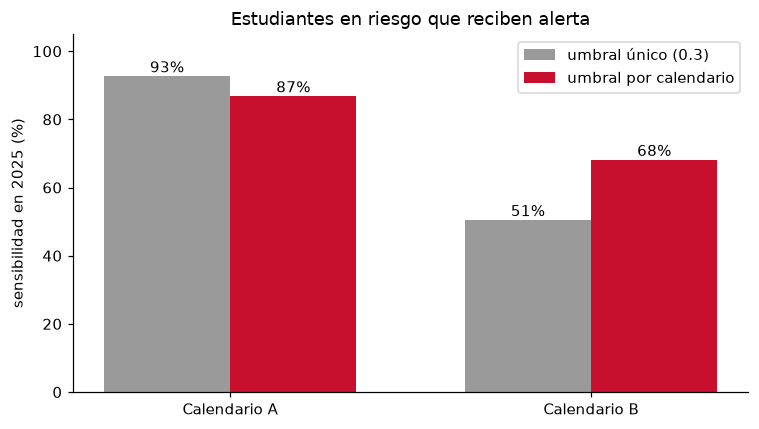

In [22]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(2); ancho = 0.35
s_unico = [recall_score(y_te[test.cole_calendario.values == c], (p_te >= UMBRAL)[test.cole_calendario.values == c]) for c in "AB"]
s_cal = [recall_score(y_te[test.cole_calendario.values == c], pred_te[test.cole_calendario.values == c]) for c in "AB"]
b1 = ax.bar(x - ancho / 2, np.array(s_unico) * 100, ancho, color=GRIS, label=f"umbral único ({UMBRAL})")
b2 = ax.bar(x + ancho / 2, np.array(s_cal) * 100, ancho, color=ROJO, label="umbral por calendario")
ax.bar_label(b1, fmt="%.0f%%"); ax.bar_label(b2, fmt="%.0f%%")
ax.set_xticks(x, ["Calendario A", "Calendario B"]); ax.set_ylabel("sensibilidad en 2025 (%)"); ax.set_ylim(0, 105)
ax.set_title("Estudiantes en riesgo que reciben alerta"); ax.legend(); plt.tight_layout(); plt.show()

- **Por género, naturaleza y estrato**, la precisión de las alertas es parecida, cerca de 5 de cada 10, y el riesgo estimado promedio coincide con el porcentaje real de cada grupo. El modelo no sobreestima ni subestima sistemáticamente a ninguno.
- La sensibilidad es más alta donde más estudiantes están en riesgo (colegios oficiales, estratos 1 y 2). Es lo esperado y va en línea con el objetivo de llegar primero a quien más lo necesita.
- El problema real era el **calendario B**: con un umbral único solo recibía alerta la mitad de sus estudiantes en riesgo. Con el umbral por calendario sube a cerca de dos tercios. No llega al 85 % porque en 2025 los estudiantes de calendario B se parecieron menos a los de 2024. El costo es que en B la precisión baja: más alertas que no se cumplen.

Es un intercambio que dejamos explícito. Preferimos que un colegio de calendario B revise algunos estudiantes de más, a que deje sin alerta a uno de cada dos estudiantes en riesgo.

## 10. Monitoreo: ¿los datos nuevos se parecen a los de entrenamiento?
Un modelo desplegado se degrada cuando la población cambia. Para detectarlo usamos el **PSI (Population Stability Index)**, que compara la distribución de cada variable en los datos nuevos contra la de entrenamiento. La regla que se usa en la industria es: menos de 0,10, estable; entre 0,10 y 0,25, revisar; más de 0,25, reentrenar.

In [23]:
def psi(ref, nuevo):
    cats = sorted(set(ref) | set(nuevo))
    a = ref.value_counts(normalize=True).reindex(cats, fill_value=0) + 1e-4
    b = nuevo.value_counts(normalize=True).reindex(cats, fill_value=0) + 1e-4
    return float(((b - a) * np.log(b / a)).sum())
tabla_psi = pd.DataFrame([{"variable": c, "PSI 2024": psi(train[c], v2024[c]), "PSI 2025": psi(train[c], test[c])} for c in VARIABLES])
tabla_psi["estado 2025"] = np.select([tabla_psi["PSI 2025"] > 0.25, tabla_psi["PSI 2025"] > 0.10], ["reentrenar", "revisar"], "estable")
display(tabla_psi.sort_values("PSI 2025", ascending=False).round(3))

,variable,PSI 2024,PSI 2025,estado 2025
12,grupo_edad,0.109,0.135,revisar
8,fami_educacionmadre,0.051,0.064,estable
7,fami_tienecomputador,0.050,0.055,estable
0,cole_jornada,0.030,0.054,estable
9,fami_educacionpadre,0.046,0.047,estable
6,fami_tieneinternet,0.040,0.040,estable
10,fami_estratovivienda,0.065,0.037,estable
4,cole_bilingue,0.322,0.002,estable
5,cole_caracter,0.660,0.002,estable
2,cole_naturaleza,0.001,0.001,estable


En 2025 ninguna variable pasa de 0,25. La que más cambia es la **edad** (zona de "revisar"), porque cada vez llegan menos estudiantes con extraedad al examen. Esta misma medición quedó dentro de la app: cuando un colegio sube su grupo, puede ver si se parece a los datos con que se entrenó el modelo. El plan es reentrenar cada vez que el ICFES publique un año nuevo, o antes si alguna variable pasa de 0,25.

## 11. Exportar el modelo para el despliegue
La app web no carga TensorFlow, porque pesaría más de un gigabyte y demoraría el arranque en un servidor gratuito. Guardamos solo lo necesario:
- **Los pesos y sesgos** de cada capa (`pesos_mlp.npz`).
- **Las categorías** de cada variable, en el mismo orden del one-hot.
- **La función de calibración** y **los umbrales** (`modelo_meta.json`).

En la app, el *forward pass* se hace con NumPy, igual que lo calculamos a mano en clase: `z = a·W + b`, ReLU en las capas ocultas y sigmoide en la salida. Antes de confiar en eso, comprobamos que da **lo mismo** que Keras.

In [24]:
pesos = [w for capa in modelo.layers if isinstance(capa, layers.Dense) for w in capa.get_weights()]
for k in range(0, len(pesos), 2):
    print(f"Capa {k // 2 + 1}: W {pesos[k].shape}  b {pesos[k + 1].shape}")

def forward_numpy(X):
    a, n = X, len(pesos) // 2
    for k in range(n):
        z = a @ pesos[2 * k] + pesos[2 * k + 1]
        a = np.maximum(z, 0) if k < n - 1 else 1 / (1 + np.exp(-z))   # ReLU en ocultas, sigmoide en la salida
    return a.ravel()

# Un estudiante paso a paso
x = X_te[:1]; z1 = x @ pesos[0] + pesos[1]; a1 = np.maximum(z1, 0)
print(f"\nEstudiante de 2025: {int(x.sum())} unos en un vector de {x.shape[1]} entradas")
print(f"Capa 1: z1 = x·W1 + b1 -> {z1.shape}; después de ReLU quedan {int((a1 > 0).sum())} neuronas activas de {a1.shape[1]}")
print(f"Probabilidad NumPy: {forward_numpy(x)[0]:.6f} | Keras: {modelo.predict(x, verbose=0)[0, 0]:.6f}")

diferencia = np.max(np.abs(forward_numpy(X_te) - p_te_cruda))
print(f"\nDiferencia máxima NumPy vs Keras en los 20.764 estudiantes de 2025: {diferencia:.2e}")
assert diferencia < 1e-5

Capa 1: W (72, 128)  b (128,)
Capa 2: W (128, 64)  b (64,)
Capa 3: W (64, 1)  b (1,)

Estudiante de 2025: 13 unos en un vector de 72 entradas
Capa 1: z1 = x·W1 + b1 -> (1, 128); después de ReLU quedan 66 neuronas activas de 128
Probabilidad NumPy: 0.013816 | Keras: 0.013816

Diferencia máxima NumPy vs Keras en los 20.764 estudiantes de 2025: 1.19e-07


In [25]:
destino = Path("/content/modelos" if IS_COLAB else "../modelos"); destino.mkdir(exist_ok=True)
np.savez(destino / "pesos_mlp.npz", *pesos)
categorias = {c: list(map(str, cs)) for c, cs in zip(VARIABLES, pre.named_transformers_["cat"].categories_)}
meta = {"variables": VARIABLES, "categorias": categorias, "umbral": UMBRAL, "umbral_calendario": UMBRAL_CAL,
        "iso_x": list(map(float, isotonica.X_thresholds_)), "iso_y": list(map(float, isotonica.y_thresholds_)),
        "referencia": {c: train[c].value_counts(normalize=True).to_dict() for c in VARIABLES},
        "arquitectura": {**MEJOR, "capas": "-".join(map(str, MEJOR["capas"]))}, "prevalencia_train": float(y_tr.mean())}
json.dump(meta, open(destino / "modelo_meta.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
modelo.save(destino / "modelo_mlp_final.keras")
print("Archivos para la app:", sorted(p.name for p in destino.iterdir()))

Archivos para la app: ['ejemplo_grupo.csv', 'fondo_explicaciones.csv', 'modelo_meta.json', 'modelo_mlp_final.keras', 'paridad_2025.csv', 'pesos_mlp.npz', 'resultados_resumen.json']


## 12. Conclusiones
1. **La búsqueda de hiperparámetros confirmó que el problema era el sobreajuste, no la falta de capacidad.** La mejor red (128-64 con Dropout 0,3, L2 y tasa de aprendizaje baja) mejora a la V3 de forma pequeña pero estadísticamente real, y entrena estable durante muchas más épocas.
2. **Con estas 13 variables hay un techo cerca de 0,75 de AUC**, que comparten la red y Gradient Boosting. Para subirlo harían falta datos del propio colegio, como notas o asistencia, no un modelo más complejo.
3. **El modelo ya es útil para priorizar:** si el colegio solo puede acompañar al 10 % de sus estudiantes, 8 de cada 10 de la lista sí estaban en riesgo.
4. **Las probabilidades están calibradas y se pueden leer como porcentajes reales**, y los umbrales por calendario corrigen la brecha que el modelo tenía con los colegios de calendario B.
5. **El modelo quedó exportado** con una implementación de NumPy idéntica a Keras, lista para la app web pública. Además tiene monitoreo de cambios en los datos y un plan de reentrenamiento.

**Limitaciones:** solo Cali; sin historial académico; el umbral de calendario B no alcanza la meta del 85 % en 2025; y la validación con docentes reales es un proceso que apenas empieza (ver documento).